# Logic gate implemented with 3 MZIs

This notebook contains code that simulates circuit made of 3 ideal MZIs connected in tringular configuration. \
The objective is to find optimal phase shifts to imitate logic operations with unitary operators given by MZIs.

It is based on: https://doi.org/10.1016/j.optlastec.2023.109703

In [8]:
%%capture

# Install dependencies specified in pyproject.toml
!uv pip install -r pyproject.toml

# Import modules
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Transfer-matrix method

Cell below provide code that generates matrix for each element present in the circuit, namely:

## Light source vector
Representing waves on 2 channels:
$
\mathbf{E}(A_1, A_2, \psi_1, \psi_2)
= \begin{bmatrix} 
    A_1 e^{i \psi_1} \\ 
    A_2 e^{i \psi_2} 
\end{bmatrix}
$

Representing waves on 3 channels:
$
\mathbf{E}(A_1, A_2, A_3, \psi_1, \psi_2, \psi_3)
= \begin{bmatrix} 
    A_1 e^{i \psi_1} \\ 
    A_2 e^{i \psi_2} \\
    A_3 e^{i \psi_3} \\
\end{bmatrix}
$

## Directional coupler
Idealized, 2x2 beam splitter, with 50:50 splitting ratio
$$
\mathbf{DC}
= \frac{1}{\sqrt{2}} \begin{bmatrix}
    1 & i \\
    i & 1 
\end{bmatrix}
$$

## Phase shift
Applied just for upper signal
$$
\mathbf{P}(\phi) 
= \begin{bmatrix} 
    e^{i \phi} & 0 \\
    0 & 1 
\end{bmatrix}
$$

## Mach–Zehnder interferometer
With phase shift applied on internal, upper arm
$$
\mathbf{MZI}(\theta)
= \mathbf{DC} \cdot \mathbf{P}(\theta) \cdot \mathbf{DC}
= \frac{1}{\sqrt{2}} \begin{bmatrix} 
    1 & i \\
    i & 1
\end{bmatrix} \cdot \begin{bmatrix}
    e^{i \theta} & 0 \\
    0 & 1
\end{bmatrix} \cdot \frac{1}{\sqrt{2}} \begin{bmatrix} 
    1 & i \\
    i & 1 
\end{bmatrix}
$$

$$
\mathbf{MZI}(\theta)
= \frac{1}{2} \begin{bmatrix}
    e^{i\theta} - 1 & i(e^{i\theta} + 1) \\ 
    i(e^{i\theta} + 1) & 1 - e^{i\theta} 
\end{bmatrix}
$$

## Mach–Zehnder interferometer with phase shift
With phase shift applied on internal upper arm and output upper arm
$$
\mathbf{MZIP}(\theta, \phi)
= \mathbf{P}(\phi) \cdot \mathbf{MZI}(\theta)
= \begin{bmatrix}
    e^{i \phi} & 0 \\
    0 & 1
\end{bmatrix} \cdot \frac{1}{2} \begin{bmatrix}
    e^{i\theta} - 1 & i(e^{i\theta} + 1) \\ 
    i(e^{i\theta} + 1) & 1 - e^{i\theta} 
\end{bmatrix}
$$

$$
\mathbf{MZIP}(\theta, \phi) = \frac{1}{2} \begin{bmatrix}
    e^{i\phi}(e^{i\theta} - 1) & i e^{i\phi}(e^{i\theta} + 1) \\
    i(e^{i\theta} + 1) & 1 - e^{i\theta}
\end{bmatrix} 
$$

## Logic cell
3MZIs with 6 phase shifts connected in triangular configuration
$$
\mathbf{U}(\theta_1, \phi_1, \theta_2, \phi_2, \theta_3, \phi_3)
= \underbrace{\begin{bmatrix}
    \frac{1}{2}e^{i\phi_3}(e^{i\theta_3} - 1) & \frac{i}{2}e^{i\phi_3}(e^{i\theta_3} + 1) & 0 \\
    \frac{i}{2}(e^{i\theta_3} + 1) & \frac{1}{2}(1 - e^{i\theta_3}) & 0 \\
    0 & 0 & 1
\end{bmatrix}}_{\mathbf{MZIP}_3} \cdot \underbrace{\begin{bmatrix}
    1 & 0 & 0 \\
    0 & \frac{1}{2}e^{i\phi_2}(e^{i\theta_2} - 1) & \frac{i}{2}e^{i\phi_2}(e^{i\theta_2} + 1) \\
    0 & \frac{i}{2}(e^{i\theta_2} + 1) & \frac{1}{2}(1 - e^{i\theta_2})
\end{bmatrix}}_{\mathbf{MZIP}_2} \cdot \underbrace{\begin{bmatrix}
    \frac{1}{2}e^{i\phi_1}(e^{i\theta_1} - 1) & \frac{i}{2}e^{i\phi_1}(e^{i\theta_1} + 1) & 0 \\
    \frac{i}{2}(e^{i\theta_1} + 1) & \frac{1}{2}(1 - e^{i\theta_1}) & 0 \\
    0 & 0 & 1
\end{bmatrix}}_{\mathbf{MZIP}_1}
$$

## Output signal
$$
\mathbf{E_{out}} = \mathbf{U}(\theta_1, \phi_1, \theta_2, \phi_2, \theta_3, \phi_3) \mathbf{E}(A_1, A_2, A_3, \psi_1, \psi_2, \psi_3)
$$

$$
\underbrace{\begin{bmatrix}
    \mathbf{E_{out_1}} \\
    \mathbf{E_{out_2}} \\
    \mathbf{E_{out_3}}
\end{bmatrix}}_{output}
= \underbrace{\begin{bmatrix}
    \frac{1}{2}e^{i\phi_3}(e^{i\theta_3} - 1) & \frac{i}{2}e^{i\phi_3}(e^{i\theta_3} + 1) & 0 \\
    \frac{i}{2}(e^{i\theta_3} + 1) & \frac{1}{2}(1 - e^{i\theta_3}) & 0 \\
    0 & 0 & 1
\end{bmatrix}}_{\mathbf{MZIP}_3} \cdot \underbrace{\begin{bmatrix}
    1 & 0 & 0 \\
    0 & \frac{1}{2}e^{i\phi_2}(e^{i\theta_2} - 1) & \frac{i}{2}e^{i\phi_2}(e^{i\theta_2} + 1) \\
    0 & \frac{i}{2}(e^{i\theta_2} + 1) & \frac{1}{2}(1 - e^{i\theta_2})
\end{bmatrix}}_{\mathbf{MZIP}_2} \cdot \underbrace{\begin{bmatrix}
    \frac{1}{2}e^{i\phi_1}(e^{i\theta_1} - 1) & \frac{i}{2}e^{i\phi_1}(e^{i\theta_1} + 1) & 0 \\
    \frac{i}{2}(e^{i\theta_1} + 1) & \frac{1}{2}(1 - e^{i\theta_1}) & 0 \\
    0 & 0 & 1
\end{bmatrix}}_{\mathbf{MZIP}_1}
\underbrace{\begin{bmatrix} 
    A_1 e^{i \psi_1} \\ 
    A_2 e^{i \psi_2} \\
    A_3 e^{i \psi_3} \\
\end{bmatrix}}_{input}
$$

In [11]:
# 2 port light source 
E2 = lambda A1, A2, psi1, psi2: np.array(
    [A1 * np.exp(1j * psi1), 
     A2 * np.exp(1j * psi2)],
    dtype=np.complex128,
)

# 3 port light source
E3 = lambda A1, A2, A3, psi1, psi2, psi3: np.array(
    [A1 * np.exp(1j * psi1), 
     A2 * np.exp(1j * psi2),
     A3 * np.exp(1j * psi3)],
    dtype=np.complex128,
)

# Directional coupler 50:50 
DC = (1.0/np.sqrt(2)) * np.array([
    [1, 1j],
    [1j, 1],
], dtype=np.complex128)

# Phase shift (upper signal)
P = lambda phi: np.array(
    [[np.exp(1j * phi), 0],
     [0, 1]],
    dtype=np.complex128,
)

# MZI
MZI = lambda theta: DC @ P(theta) @ DC

# MZI + P
MZIP = lambda theta, phi: P(phi) @ MZI(theta)

# Helper for printing matrices
def print_matrix(M):
    formatted = np.array2string(
        M,
        precision=2,
        suppress_small=True,
        max_line_width=100,
        separator="|",
    )
    print(formatted)

# Helper for embedding matrices
def embed_3x3(U2: np.ndarray, i: int, j: int) -> np.ndarray:
    # 3x3 identity matrix
    M3 = np.eye(3, dtype=np.complex128)
    M3[np.ix_([i, j], [i, j])] = U2
    return M3

# Logic cell ()
def logic_unit(p):
    t1, p1, t2, p2, t3, p3 = p
    
    M1 = embed_3x3(MZIP(t1, p1), 0, 1)
    M2 = embed_3x3(MZIP(t2 ,p2), 1, 2)
    M3 = embed_3x3(MZIP(t3 ,p3), 0, 1)

    return M3 @ M2 @ M1

# Mach-Zehnder interferometer simulation

Cell below investigate the behavior of MZI model using previously defined transfer matrices. \
It performs a sweep across the phase shift parameter $\theta$ from $0$ to $2\pi$ and plot E field intensity and it's phase on output ports.

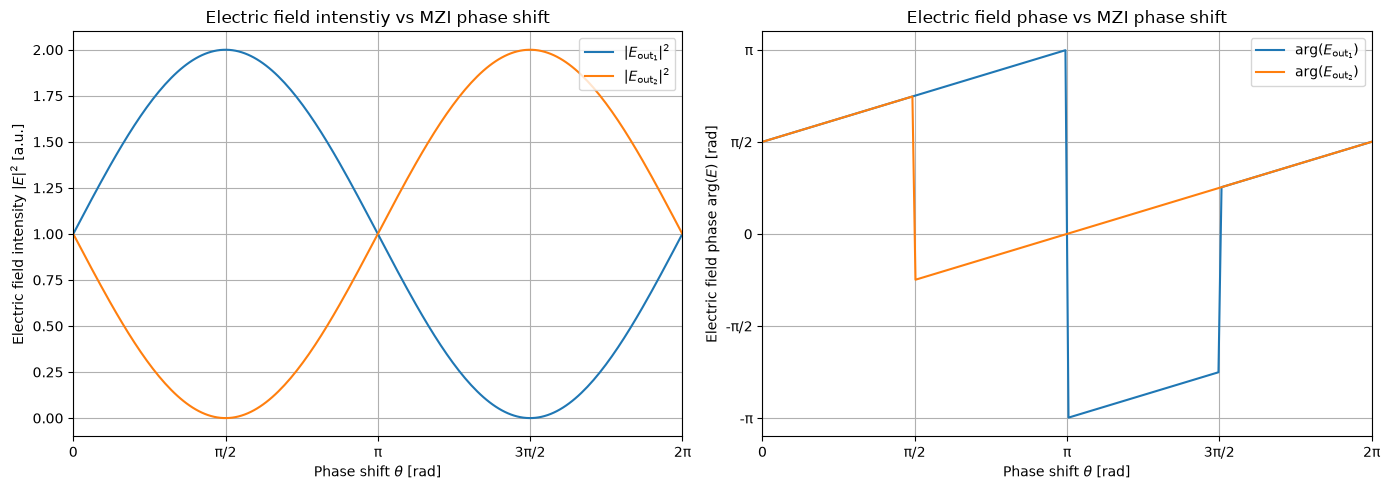

In [40]:
# Input signal
e_in = E2(1,1,0,0)

# Thetas vector from 0 to 2pi
thetas = np.linspace(0.0, 2.0 * np.pi, 200)

# MZI matrices for all thetas
mzis = np.array([MZI(t) for t in thetas])
e_out = mzis @ e_in

# Intensity at output channels
e_intensity = np.abs(e_out)**2

# Phase at output channels
e_phase = np.angle(e_out)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

# E intensity plot
ax1.set_title("Electric field intenstiy vs MZI phase shift")
ax1.plot(thetas, e_intensity[:, 0], label=r"$|E_{\text{out}_1}|^2$")
ax1.plot(thetas, e_intensity[:, 1], label=r"$|E_{\text{out}_2}|^2$")
ax1.set_ylabel(r"Electric field intensity $|E|^2$ [a.u.]")
ax1.set_xlabel(r"Phase shift $\theta$ [rad]")
ax1.set_xlim(0.0, 2.0 * np.pi)
ax1.set_xticks([0.0, 0.5 * np.pi, np.pi, 1.5 * np.pi, 2.0 * np.pi])
ax1.set_xticklabels(["0", "π/2", "π", "3π/2", "2π"])
ax1.legend(loc="upper right")
ax1.grid(True)

# E phase plot
ax2.set_title("Electric field phase vs MZI phase shift")
ax2.plot(thetas, e_phase[:, 0], label=r"$\arg(E_{\text{out}_1})$")
ax2.plot(thetas, e_phase[:, 1], label=r"$\arg(E_{\text{out}_2})$")
ax2.set_ylabel(r"Electric field phase $\arg(E)$ [rad]")
ax2.set_xlabel(r"Phase shift $\theta$ [rad]")
ax2.set_ylim(-np.pi*1.1, np.pi*1.1)
ax2.set_yticks([-np.pi, -0.5 * np.pi, 0.0, 0.5 * np.pi, np.pi])
ax2.set_yticklabels(["-π", "-π/2", "0", "π/2", "π"])
ax2.legend(loc="upper right")
ax2.grid(True)


plt.tight_layout()
plt.show()

# Phases optimization

Cell below uses gradient descent algorithm to find optimal phase shifts resulting in desire behavior.

Best MSE loss: 0.008993
Best phases [t1, p1, t2, p2, t3, 0.0]: [ 1.57 -1.88 -0.01 -1.08 -2.44  0.  ]
  A=0, B=0, C=1 | target Y=0 | power_out=0.1176
  A=0, B=1, C=1 | target Y=0 | power_out=0.1032
  A=1, B=0, C=1 | target Y=0 | power_out=0.1032
  A=1, B=1, C=1 | target Y=1 | power_out=0.9712


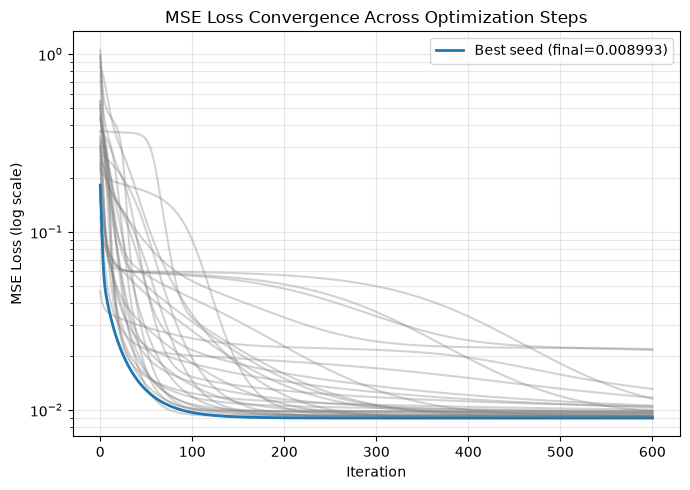

In [48]:
and_cases = [
    # A | B | C | Y
    (0, 0, 1, 0),
    (0, 1, 1, 0),
    (1, 0, 1, 0),
    (1, 1, 1, 1),
]

# Perform simulation on full device
def logic_unit_sim(e_in, p):
    p = np.asarray(p, dtype=np.float64).copy()
    p[-1] = 0.0

    U = logic_unit(p)
    e_out = U @ e_in

    return e_out

# Calculate MSE loss on output port 0
def loss(cases, p):
    total_loss = 0.0
    for a, b, c, y in cases:
        e_in = E3(a, b, c, 0, 0, 0)
        e_out = logic_unit_sim(e_in, p)
        e_intensity = np.abs(e_out)**2
        intensity_error = np.abs(y)**2 - e_intensity[0]
        total_loss += intensity_error**2

    return total_loss / len(cases)

# Finite-difference gradient (central difference)
def grad_fd(cases, p, eps=1e-6):
    g = np.zeros_like(p, dtype=np.float64)
    for k in range(len(p) - 1):  # p[-1] is fixed to 0.0
        p_plus = p.copy()
        p_minus = p.copy()
        p_plus[k] += eps
        p_minus[k] -= eps
        g[k] = (loss(cases, p_plus) - loss(cases, p_minus)) / (2.0 * eps)
    return g

best_p = None
best_loss = np.inf
best_history = None
all_histories = []

for seed in range(30):
    rng = np.random.default_rng(seed)
    p_cur = rng.uniform(-np.pi, np.pi, size=6)
    p_cur[-1] = 0.0
    lr = 0.25
    
    history = []
    for _ in range(600):
        l_step = loss(and_cases, p_cur)
        history.append(l_step)
        p_cur = p_cur - lr * grad_fd(and_cases, p_cur)
        p_cur[-1] = 0.0

    l_cur = loss(and_cases, p_cur)
    history.append(l_cur)
    all_histories.append(history)

    if l_cur < best_loss:
        best_loss = l_cur
        best_p = p_cur.copy()
        best_history = history

Best MSE loss: 0.008993
Best phases [t1, p1, t2, p2, t3, 0.0]: [ 1.57 -1.88 -0.01 -1.08 -2.44  0.  ]
  A=0, B=0, C=1 | target Y=0 | power_out=0.1176
  A=0, B=1, C=1 | target Y=0 | power_out=0.1032
  A=1, B=0, C=1 | target Y=0 | power_out=0.1032
  A=1, B=1, C=1 | target Y=1 | power_out=0.9712


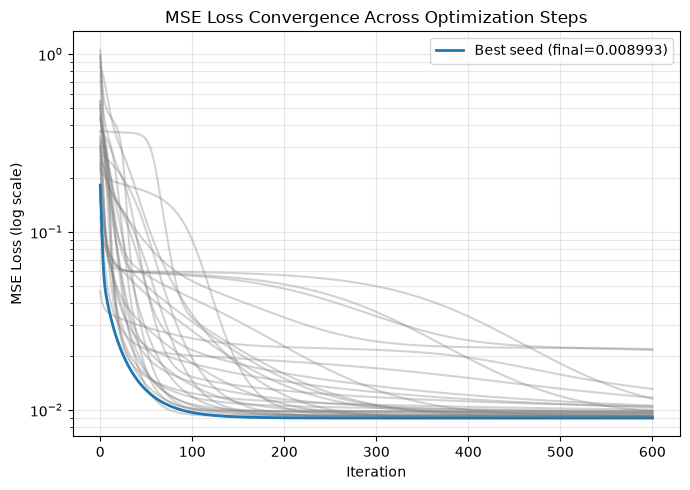

In [49]:
print(f"Best MSE loss: {best_loss:.6f}")
print("Best phases [t1, p1, t2, p2, t3, 0.0]:", np.round(best_p, 2))
for a, b, c, y in and_cases:
    e_in = E3(a, b, c, 0, 0, 0)
    p_out = float(np.abs(logic_unit_sim(e_in, best_p)[0]) ** 2)
    print(f"  A={a}, B={b}, C={c} | target Y={y} | power_out={p_out:.4f}")

plt.figure(figsize=(7, 5))
for seed, hist in enumerate(all_histories):
    plt.plot(hist, alpha=0.35, color="gray")

plt.plot(best_history, color="tab:blue", linewidth=2, label=f"Best seed (final={best_loss:.6f})")
plt.yscale("log")
plt.title("MSE Loss Convergence Across Optimization Steps")
plt.xlabel("Iteration")
plt.ylabel("MSE Loss (log scale)")
plt.grid(True, which="both", alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

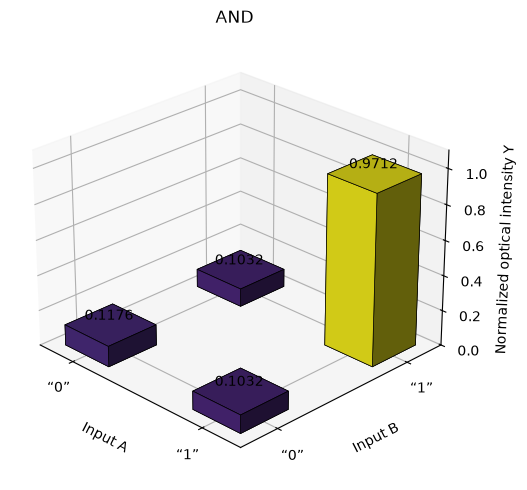

In [53]:
# 1. Calculate the 4 output powers
powers = [float(np.abs(logic_unit_sim(E3(a, b, c, 0, 0, 0), best_p)[0])**2) for a, b, c, _ in and_cases]
x = [a for a, _, _, _ in and_cases]
y = [b for _, b, _, _ in and_cases]

# 2. Setup 3D plot
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection="3d")

# Color bars by height using viridis
colors = cm.viridis(np.array(powers) / max(1.0, max(powers)))
ax.bar3d(x, y, np.zeros(4), dx=0.35, dy=0.35, dz=powers, color=colors, edgecolor="k", linewidth=0.5)

# 3. Add value labels on top of each bar
for xi, yi, zi in zip(x, y, powers):
    ax.text(xi + 0.17, yi + 0.17, zi + 0.03, f"{zi:.4f}", ha="center")

# 4. Formatting
ax.set_title("AND")
ax.set_xticks([0.17, 1.17])
ax.set_xticklabels(['“0”', '“1”'])
ax.set_yticks([0.17, 1.17])
ax.set_yticklabels(['“0”', '“1”'])
ax.set_zlim(0, 1.1)
ax.set_xlabel("Input A")
ax.set_ylabel("Input B")
ax.set_zlabel("Normalized optical intensity Y")
ax.view_init(elev=26, azim=-45)

plt.tight_layout()
plt.show()